# Step 0: Import requisite libraries

In [367]:
import json
import math
import pandas as pd
import numpy as np
import xgboost as xgb
from itertools import product
from sklearn import preprocessing, ensemble, tree
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, TunedThresholdClassifierCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, PrecisionRecallDisplay
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
import matplotlib as plt
import seaborn

threshold = 0.39

# Step 1: Import and cleaning of data

In [368]:
df_raw = pd.read_csv("Baza_customer_Telecom_v2.csv")

# Over+undersample by using combined SMOTE and Tomek links

df = df_raw
df["CHURN"].value_counts()

CHURN
No     7904
Yes     549
Name: count, dtype: int64

In [369]:
print(f"Length of dataset before cleaning: {len(df)}")
# Cleaning for PID
df = df.loc[df["PID"].notnull() & df["PID"].str.fullmatch(r"[0-9]*(SMB)?")] # Some PIDs were scientific notation (invalid); valid format is integer optionally followed by "SMB"

# Cleaning for value segment
df = df.loc[df["CRM_PID_Value_Segment"].notnull()]
df["CRM_PID_Value_Segment"] = df["CRM_PID_Value_Segment"].replace("Sliver", "Silver") # Fix assumed typo in one entry

# Cleaning for effective segment
df = df.loc[df["EffectiveSegment"].notnull()]

# Cleaning for ZIP
df = df.loc[df["Billing_ZIP"] % 1 == 0] # Remove non-integer ZIP codes (invalid; includes nulls)

# Cleaning for KA_name
df = df.loc[df["KA_name"].notnull()]
df["KA_name"] = df["KA_name"].replace("AD?", "AD") # Grouped AD? with AD under assumption that unsure attribution is correct

# Cleaning for active_subscribers
df = df.loc[df["Active_subscribers"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for not_active_subscribers
df["Not_Active_subscribers"] = df["Not_Active_subscribers"].fillna(0) # Fill nulls with 0 (assuming nulls indicate none inactive; minimum non-NaN value is 1)

# Cleaning for suspended_subscribers
df["Suspended_subscribers"] = df["Suspended_subscribers"].fillna(0) # Fill nulls with 0 (assuming nulls indicate none suspended; minimum non-NaN value is 1)

# Cleaning for total_SUBs
df = df.loc[df["Total_SUBs"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for AvgMobileRevenue
df = df.loc[df["AvgMobileRevenue "].notnull()] # Redundant (no nulls) but included for consistency
df = df.rename(columns={"AvgMobileRevenue ": "AvgMobileRevenue"}) # Remove trailing space from column name

# Cleaning for AvgFIXRevenue
df = df.loc[df["AvgFIXRevenue"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for TotalRevenue
df = df.loc[df["TotalRevenue"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for ARPU
df = df.loc[df["ARPU"].notnull()]

# Cleaning for CHURN
df = df.loc[df["CHURN"].isin(["No", "Yes"])] # Remove invalid CHURN values (only valid values are "No" and "Yes"); redundant (no invalids) but included for consistency

print(f"Length of dataset after cleaning: {len(df)}") # Small length change, hence valid to discard nulls/invalid entries

# Feature engineering
df["inactive_ratio"] = df["Not_Active_subscribers"]/df["Total_SUBs"]
df["suspended_ratio"] = df["Suspended_subscribers"]/df["Total_SUBs"]

# Source - https://stackoverflow.com/a/48035423
# Posted by BENY, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-02, License - CC BY-SA 4.0

df.apply(lambda x : pd.factorize(x)[0]).corr(method='pearson', min_periods=1)
segment_order = (df.groupby("CRM_PID_Value_Segment")["TotalRevenue"]
                 .mean()
                 .sort_values()
                 .index
                 .tolist())

Length of dataset before cleaning: 8453
Length of dataset after cleaning: 8419


# Step 2: Data Preprocessing

In [370]:
X = df.drop(columns=["CHURN"])
y = df["CHURN"].map({"No": 0, "Yes": 1}) # Convert CHURN to binary values (0 for No, 1 for Yes)

X["PID_is_SMB"] = X["PID"].str.endswith("SMB").astype("string") # Create binary feature indicating if PID ends with "SMB"
X["PID"]=X["PID"].str.replace("SMB", "").astype(int) # Remove "SMB" from PID and convert to integer

# Definition of categorical and numerical features for preprocessing
cat_features = [
    "CRM_PID_Value_Segment", 
    "EffectiveSegment", 
    "Billing_ZIP", 
    "KA_name", 
    "PID_is_SMB"]
num_features = [
    "Active_subscribers", 
    "Not_Active_subscribers", 
    "Suspended_subscribers", 
    "Total_SUBs", 
    "AvgMobileRevenue", 
    "AvgFIXRevenue", 
    "TotalRevenue", 
    "ARPU",
    ]

# Selection of features for model training

train_features = cat_features + num_features

class_weights = {0: len(y == 1), 1: len(y == 0)}

# train_features = [
#     "PID_is_SMB",
#     "CRM_PID_Value_Segment", 
#     "Active_subscribers",
#     "AvgMobileRevenue",
#     "TotalRevenue"
#     ]

X = X[train_features]

# Definition of ColumnTransformer for preprocessing
c_transformer = ColumnTransformer(
    transformers=[
        ("categorical", preprocessing.OneHotEncoder(handle_unknown="ignore"), list(set(cat_features) & set(train_features)) ),
        ("numerical", "passthrough", list(set(num_features) & set(train_features)) )
    ]
)


# print(f"Column transformer has categorical features {list(set(cat_features) & set(train_features))} and numerical features {list(set(num_features) & set(train_features))}")


# XGBoost prep
for col in (set(cat_features) & set(train_features)):
    X[col] = X[col].astype('category')

# Manual comparison selected 0.5 as the best SMOTETomek target by validation macro-F1.
smt = SMOTETomek(sampling_strategy=1/7, random_state=42)

# Train/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)
# Fit preprocessor separately so the validation set can be transformed in the
# same way as the training set before each XGBoost eval round.
X_train_proc = c_transformer.fit_transform(X_train, y_train)
X_valid_proc = c_transformer.transform(X_valid)
X_test_proc = c_transformer.transform(X_test)

# Resample only the transformed training data. The validation/test sets should
# remain in their original class distribution for evaluation.
X_train_res, y_train_res = smt.fit_resample(X_train_proc, y_train)

# XGBoost model using a proper eval set.
clf = xgb.XGBClassifier(
    tree_method="hist",
    n_estimators=5000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=1,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=0.0,
    reg_lambda=3,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=(y_train_res == 0).sum() / (y_train_res == 1).sum(),
    early_stopping_rounds=300,
    random_state=42,
)

# Fit model using the transformed validation set.
clf.fit(
    X_train_res,
    y_train_res,
    eval_set=[(X_valid_proc, y_valid)],
    verbose=False,
)

# Predict on test set
y_pred_p = clf.predict_proba(X_test_proc)
t_df = pd.DataFrame(X_test)
t_df["Predicted_Churn_Probability"] = y_pred_p[:, 1] # Get probabilities for positive class (CHURN = Yes)
t_df["Predicted_Churn"] = (t_df["Predicted_Churn_Probability"] >= threshold).astype(int) # Convert probabilities to binary predictions using threshold of 0.5
t_df["Actual_Churn"] = y_test.values # Add actual CHURN values for comparison
t_df["Prediction_type"] = np.select(
    [
        (t_df["Predicted_Churn"] == 1) & (t_df["Actual_Churn"] == 1),
        (t_df["Predicted_Churn"] == 0) & (t_df["Actual_Churn"] == 0),
        (t_df["Predicted_Churn"] == 1) & (t_df["Actual_Churn"] == 0),
        (t_df["Predicted_Churn"] == 0) & (t_df["Actual_Churn"] == 1)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

# Evaluate model performance
y_pred = y_pred_p[:, 1] >= threshold
print(classification_report(y_test, y_pred))
print("Test confusion matrix with threshold", (str(threshold) + ":\n"), confusion_matrix(y_test, y_pred))
train_prob = clf.predict_proba(X_train_proc)[:, 1]
train_pred = (train_prob >= threshold).astype(int)
print(confusion_matrix(y_train, train_pred))
t_df.sort_values(by="Predicted_Churn_Probability", ascending=False).to_csv("Predicted_Churn_Results.csv", index=False) # Save predictions to CSV for further analysis
t_df.sort_values(by="Predicted_Churn_Probability", ascending=False).head(20) # Sort by predicted probability for easier analysis

              precision    recall  f1-score   support

           0       0.94      0.75      0.83      1575
           1       0.08      0.34      0.14       109

    accuracy                           0.72      1684
   macro avg       0.51      0.54      0.48      1684
weighted avg       0.89      0.72      0.79      1684

Test confusion matrix with threshold 0.39:
 [[1176  399]
 [  72   37]]
[[3792 1249]
 [ 216  131]]


,CRM_PID_Value_Segment,EffectiveSegment,Billing_ZIP,KA_name,PID_is_SMB,Active_subscribers,Not_Active_subscribers,Suspended_subscribers,Total_SUBs,AvgMobileRevenue,AvgFIXRevenue,TotalRevenue,ARPU,Predicted_Churn_Probability,Predicted_Churn,Actual_Churn,Prediction_type
4643,Gold,VSE,4004.0,Daniela Stefanova,False,12,0.0,0.0,12,313.00,0.0,313.00,26.08,0.398412,1,0,False Positive
7622,Platinum,VSE,6600.0,RJ,False,4,1.0,0.0,5,328.67,0.0,328.67,82.17,0.398412,1,0,False Positive
7221,SME,SME,6300.0,RJ,False,30,16.0,0.0,46,449.00,0.0,449.00,14.97,0.398412,1,0,False Positive
7560,Platinum,VSE,4300.0,Ginka Vachkova,False,23,2.0,0.0,25,347.33,0.0,347.33,15.10,0.398412,1,0,False Positive
4505,Gold,VSE,6100.0,AD,False,10,2.0,0.0,12,292.50,0.0,292.50,29.25,0.398412,1,0,False Positive
4514,Silver,VSE,6100.0,AD,False,12,3.0,0.0,15,293.50,0.0,293.50,24.46,0.398412,1,0,False Positive
4425,Gold,VSE,4000.0,Daniela Stefanova,False,15,4.0,0.0,19,281.17,0.0,281.17,18.74,0.398412,1,0,False Positive
4944,Platinum,VSE,6000.0,AD,False,23,0.0,0.0,23,387.00,0.0,387.00,16.83,0.398412,1,0,False Positive
4829,Gold,VSE,6400.0,AD,False,14,0.0,0.0,14,357.50,0.0,357.50,25.54,0.398412,1,0,False Positive
7392,Platinum,VSE,4000.0,MT,False,16,7.0,0.0,23,490.00,0.0,490.00,30.63,0.398412,1,0,False Positive


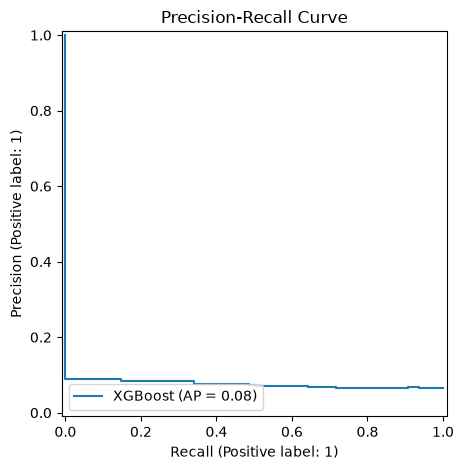

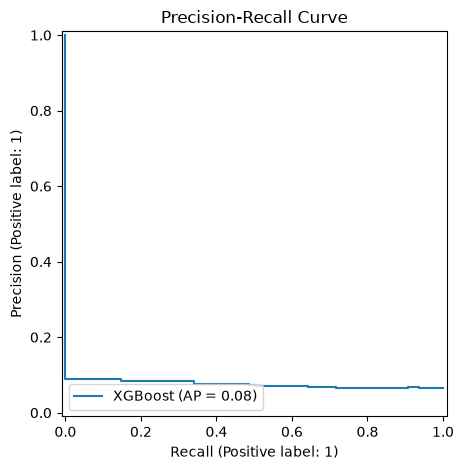

In [371]:
# Precision-recall curves require the positive-class probability, not both probability columns.
pr_display = PrecisionRecallDisplay.from_predictions(
    y_test,
    y_pred_p[:, 1],
    name="XGBoost",
)
pr_display.ax_.set_title("Precision-Recall Curve")
pr_display.ax_.figure.tight_layout()
pr_display.ax_.figure

In [372]:
t_df[t_df["Prediction_type"] == "False Positive"].sort_values(by="Predicted_Churn_Probability", ascending=False).head(20) # Sort by predicted probability for easier analysis

,CRM_PID_Value_Segment,EffectiveSegment,Billing_ZIP,KA_name,PID_is_SMB,Active_subscribers,Not_Active_subscribers,Suspended_subscribers,Total_SUBs,AvgMobileRevenue,AvgFIXRevenue,TotalRevenue,ARPU,Predicted_Churn_Probability,Predicted_Churn,Actual_Churn,Prediction_type
7242,Platinum,VSE,6480.0,AD,False,29,0.0,0.0,29,430.33,0.0,430.33,14.84,0.398412,1,0,False Positive
4553,Gold,VSE,4000.0,AD,False,18,0.0,0.0,18,298.50,0.0,298.50,16.58,0.398412,1,0,False Positive
4957,Platinum,VSE,4150.0,AD,False,20,0.0,0.0,20,391.17,0.0,391.17,19.56,0.398412,1,0,False Positive
4891,Platinum,VSE,4230.0,AD,False,18,0.0,0.0,18,373.67,0.0,373.67,20.76,0.398412,1,0,False Positive
4505,Gold,VSE,6100.0,AD,False,10,2.0,0.0,12,292.50,0.0,292.50,29.25,0.398412,1,0,False Positive
4600,Gold,VSE,4400.0,Daniela Stefanova,False,7,3.0,0.0,10,307.17,0.0,307.17,43.88,0.398412,1,0,False Positive
7639,SME,SME,6300.0,RJ,False,21,11.0,0.0,32,319.33,0.0,319.33,15.21,0.398412,1,0,False Positive
4785,Gold,VSE,4000.0,VT,False,19,6.0,0.0,25,334.83,10.5,345.33,17.62,0.398412,1,0,False Positive
4828,Platinum,VSE,8919.0,RJ,False,30,0.0,0.0,30,356.83,0.0,356.83,11.89,0.398412,1,0,False Positive
7602,Platinum,VSE,4400.0,VT,False,31,16.0,0.0,47,478.67,0.0,478.67,15.44,0.398412,1,0,False Positive


In [373]:
from sklearn.metrics import precision_score, recall_score

# Calculate evaluation metrics separately for each CRM value segment.
# The loop follows segment_order so auc_df keeps the business-defined ordering.
auc_rows = []
for segment in segment_order:
    # Select only test-set rows that belong to the current CRM segment.
    segment_mask = X_test["CRM_PID_Value_Segment"] == segment

    # Select the actual churn labels for this segment using the same mask.
    segment_actual = y_test[segment_mask]

    # y_pred_p contains two probability columns: column 0 for No churn and
    # column 1 for Yes churn. ROC-AUC must use the positive-class probability.
    segment_probability = y_pred_p[segment_mask.to_numpy(), 1]

    # Convert probabilities to binary predictions using the global threshold.
    # Precision and recall depend on this threshold; AUC does not.
    segment_prediction = segment_probability >= threshold

    # ROC-AUC is undefined when a segment contains only one actual class.
    # Store NaN for those segments instead of raising an exception.
    segment_auc = (
        roc_auc_score(segment_actual, segment_probability)
        if segment_actual.nunique() == 2
        else np.nan
    )

    # Store one result row for the current segment. Sample counts provide
    # context because metrics from very small segments are unstable.
    auc_rows.append({
        "Segment": segment,
        "AUC": segment_auc,
        "Precision": precision_score(
            segment_actual,
            segment_prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            segment_actual,
            segment_prediction,
            zero_division=0,
        ),
        "Samples": int(segment_mask.sum()),
        "Positive_samples": int(segment_actual.sum()),
    })

# Convert the collected rows into a DataFrame for comparison and display.
auc_df = pd.DataFrame(auc_rows)
auc_df

,Segment,AUC,Precision,Recall,Samples,Positive_samples
0,Iron,0.385000,0.000000,0.000000,52,2
1,Bronze,0.527579,0.200000,0.020408,752,49
2,Silver,0.639834,0.085366,0.304348,400,23
3,SE,NaN,0.000000,0.000000,13,0
4,Lead,NaN,0.000000,0.000000,6,0
5,Gold,0.596798,0.076923,0.842105,305,19
6,SME,0.602241,0.139535,0.857143,58,7
7,Platinum,0.385768,0.077778,0.777778,98,9
